# Customer Segmentation with RFM and K-Means
**Objective:** Group an e-commerce company's customers into distinct segments based on purchasing behaviour, so each group can get targeted marketing.

**Tech stack:** Python, pandas, scikit-learn (KMeans), matplotlib, seaborn

> **Note:** `online_retail.csv` is a practice dataset in the same format as the classic UCI "Online Retail" data. For your final submission, repeat the steps on the real dataset from Kaggle (search "Online Retail"). Column names are the same, so the notebook should run with little change.

## 0. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## 1. Load data and inspect structure

In [3]:
df = pd.read_csv("online_retail.csv", parse_dates=["InvoiceDate"])
print("Shape:", df.shape)
df.head()

Shape: (35476, 7)


,InvoiceNo,CustomerID,InvoiceDate,Description,Quantity,UnitPrice,Country
0,501653,12078.0,2023-02-05 12:07:00,Tea Set,1,33.45,Spain
1,501653,12078.0,2023-02-05 12:07:00,Tea Set,2,34.02,Spain
2,511046,13017.0,2023-02-08 10:13:00,Desk Plant,1,14.43,United Kingdom
3,511046,13017.0,2023-02-08 10:13:00,Cushion Cover,6,13.95,United Kingdom
4,511046,13017.0,2023-02-08 10:13:00,Scented Candle,1,9.01,United Kingdom


In [4]:
df.info()
print()
print("Nulls per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 35476 entries, 0 to 35475
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    35476 non-null  str           
 1   CustomerID   34020 non-null  float64       
 2   InvoiceDate  35476 non-null  datetime64[us]
 3   Description  35476 non-null  str           
 4   Quantity     35476 non-null  int64         
 5   UnitPrice    35476 non-null  float64       
 6   Country      35476 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 2.8 MB

Nulls per column:
InvoiceNo         0
CustomerID     1456
InvoiceDate       0
Description       0
Quantity          0
UnitPrice         0
Country           0
dtype: int64


In [5]:
print("Cancelled invoices (start with 'C'):", df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Rows with Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Rows with UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

Cancelled invoices (start with 'C'): 524
Rows with Quantity <= 0: 524
Rows with UnitPrice <= 0: 42


**Problems found:** _List what needs cleaning before analysis (missing IDs, cancellations, zero prices...)._

## 2. Clean the data
_Checklist: handle missing values and inconsistent data_

In [6]:
n0 = len(df)

df = df.dropna(subset=["CustomerID"])                              # can't segment unknown customers
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]          # remove cancellations
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]              # remove invalid rows
df["CustomerID"] = df["CustomerID"].astype(int).astype(str)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print(f"Rows: {n0} -> {len(df)}  (removed {n0 - len(df)})")
print("Unique customers:", df["CustomerID"].nunique())

Rows: 35476 -> 33495  (removed 1981)
Unique customers: 1796


**Justification:** _Why is it correct to drop rows with no CustomerID and the cancelled orders for this analysis?_

## 3. Descriptive statistics
_Checklist: average purchase value, purchase frequency, customer lifetime value_

In [7]:
orders = df.groupby(["CustomerID", "InvoiceNo"])["TotalPrice"].sum().reset_index()

avg_order_value = orders["TotalPrice"].mean()
orders_per_customer = orders.groupby("CustomerID")["InvoiceNo"].nunique()
clv = df.groupby("CustomerID")["TotalPrice"].sum()      # simple CLV = total spend to date

print(f"Average order value:         {avg_order_value:.2f}")
print(f"Avg orders per customer:     {orders_per_customer.mean():.2f}")
print(f"Average customer lifetime value (total spend): {clv.mean():.2f}")
print(f"Median customer lifetime value: {clv.median():.2f}")

Average order value:         113.12
Avg orders per customer:     7.31
Average customer lifetime value (total spend): 826.85
Median customer lifetime value: 535.29


**Observation:** _Write 2-3 sentences about what this output shows._

## 4. Build RFM features
_Checklist: Recency, Frequency, Monetary_

In [8]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
).reset_index()
rfm.describe()

,Recency,Frequency,Monetary
count,1796.000000,1796.000000,1796.000000
mean,86.976615,7.309577,826.850501
std,95.476967,6.671098,944.947192
min,1.000000,1.000000,10.460000
25%,21.000000,3.000000,203.212500
50%,44.000000,5.000000,535.290000
75%,152.000000,9.000000,946.295000
max,360.000000,30.000000,4773.380000


**What RFM means:**
- **Recency:** days since the customer's last purchase (lower = better)
- **Frequency:** number of orders (higher = better)
- **Monetary:** total money spent (higher = better)

_Explain in your own words why these three features are good for segmenting customers._

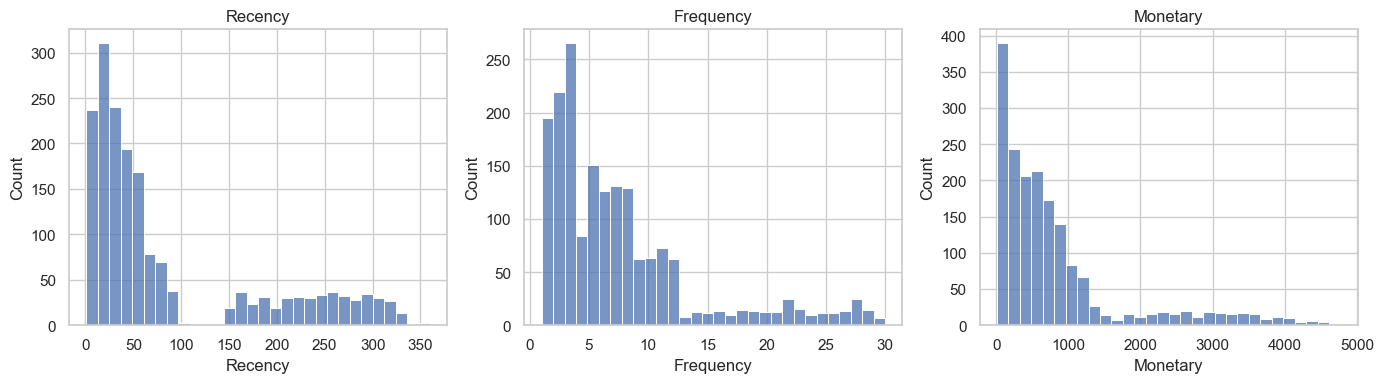

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Observation:** _Are the distributions skewed? Why can skewed data be a problem for K-Means?_

## 5. Normalise the features
_Checklist: StandardScaler before clustering_

In [10]:
# log transform reduces skew in Frequency and Monetary; then standardise
rfm_log = rfm[["Recency", "Frequency", "Monetary"]].copy()
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)
print("Scaled means (should be ~0):", X.mean(axis=0).round(3))
print("Scaled std   (should be ~1):", X.std(axis=0).round(3))

Scaled means (should be ~0): [ 0.  0. -0.]
Scaled std   (should be ~1): [1. 1. 1.]


**Why scale?** _K-Means uses distances. What would happen if Monetary (large numbers) was not scaled while Frequency (small numbers) was?_

## 6. Choose K with the Elbow Method
_Checklist: Elbow Method to determine the optimal number of clusters_

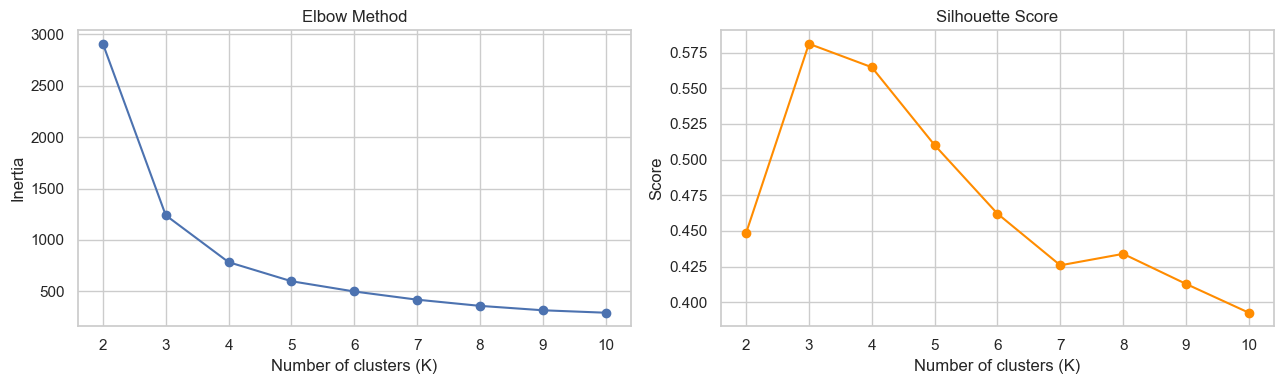

In [11]:
inertias, sil_scores = [], []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(K_range), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(K_range), sil_scores, marker="o", color="darkorange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

**Decision:** _Which K will you use and why? Look for the 'elbow' where the curve stops dropping sharply, and use the silhouette score as a second opinion._

## 7. Fit K-Means and visualise clusters
_Checklist: scatter plots of at least 2 feature combinations_

In [12]:
K = 4   # <-- change this to the value you chose in Section 6
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
rfm["Cluster"] = kmeans.fit_predict(X)
rfm["Cluster"].value_counts().sort_index()

Cluster
0    519
1    590
2    240
3    447
Name: count, dtype: int64

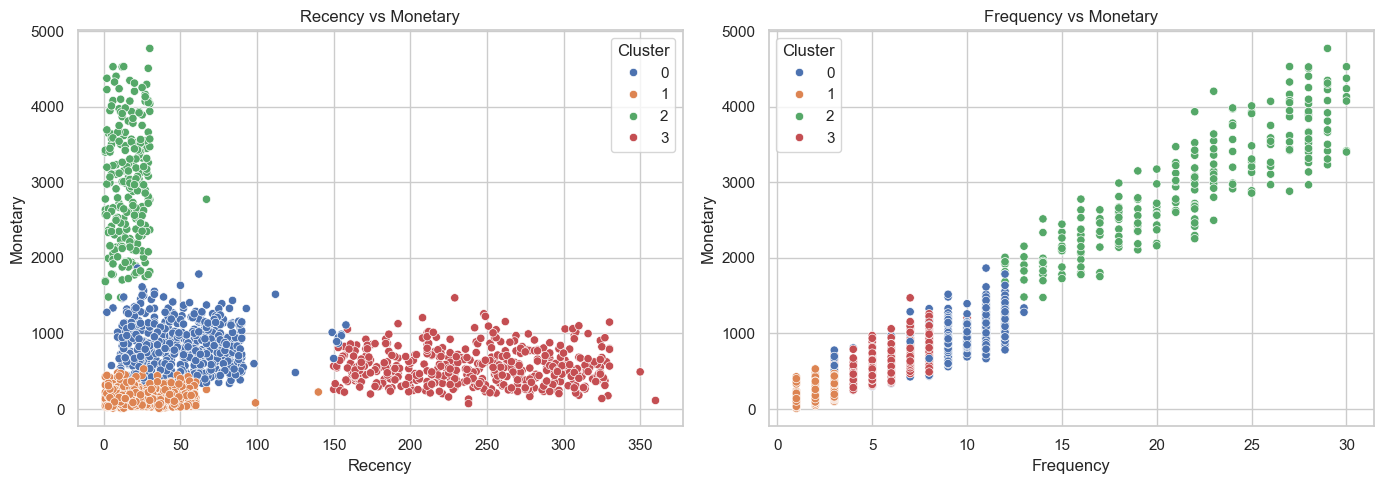

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Cluster", palette="deep", ax=axes[0])
axes[0].set_title("Recency vs Monetary")

sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Cluster", palette="deep", ax=axes[1])
axes[1].set_title("Frequency vs Monetary")

plt.tight_layout()
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 8. Profile each cluster
_Checklist: mean feature values per cluster and a description of the customer type_

In [14]:
profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
).round(1)
profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,519,50.5,8.4,840.1
1,590,30.2,2.0,152.9
2,240,16.2,21.7,2961.0
3,447,242.3,5.3,555.1


**Describe each cluster:** _Look at the table and name each group, for example "Champions", "At risk", "New customers"._
- **Cluster 0:** ...
- **Cluster 1:** ...
- **Cluster 2:** ...
- **Cluster 3:** ...

## 9. Customers per cluster
_Checklist: bar chart_

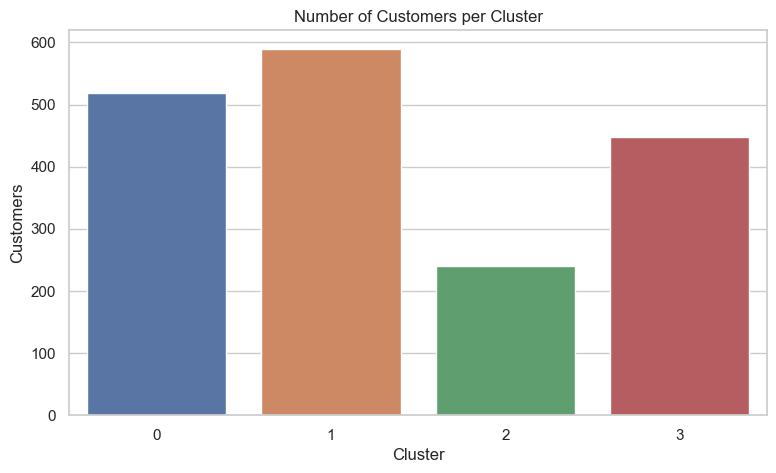

In [15]:
counts = rfm["Cluster"].value_counts().sort_index()

sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="deep", legend=False)
plt.title("Number of Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Customers")
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 10. Insights and marketing actions
_Checklist: what marketing action do you recommend for each segment?_

| Cluster | Customer type | Recommended action |
|---|---|---|
| 0 | ... | ... |
| 1 | ... | ... |
| 2 | ... | ... |
| 3 | ... | ... |

_Example of the thinking: a group that bought often but not recently could get a win-back discount; a group that spends the most could get early access to new products or a loyalty reward._